# Atomic Toy Model: Task 5 and Task 7

Task 5: float32 versus float64. Task 7: memory and scalability. The float32 data is made from the float64 data with `astype`.

Not redefined here, taken from the earlier tasks: Task 1 baseline (`pos`, `vel`, `mass`, `L`, `dt`, `k`, `r0`, `r_c`, `e_input`, `pairwise_dist`, `pair_forces`, `wall_reflection`, `Kinetic_energy`, `potential_energy`), Task 3/4 (`initial_state`, `seeds`) and Task 6 (`pair_forces_vectorized`, `forces_python`, `compile_c_library`, `median_time`).

### Setup

In [1]:
import tracemalloc  #tracks the memory python/numpy allocate, used to get peak memory
import warnings  # suppresses or controls non-critical warnings during execution
from pathlib import Path  # folder path for the C library built by compile_c_library (Task 6)

import psutil   #tells us how much free memory the computer has

try:
    from IPython.display import display #also works when the notebook is run as a plain script
except ImportError:
    display = print

pd.options.display.float_format = '{:.6g}'.format #tables show 6 significant digits

#N, L, dt, k, r0, r_c, e_input, seeds and dts are already defined in the earlier tasks
total_time = 5.0 #total simulation time for Task 5, so steps = total_time/dt = 500
seed = 0
precisions = [('float32', np.float32), ('float64', np.float64)] #name and dtype, used in the loops later

#### Baseline

The pair energy is the shifted spring energy, `potential_energy(pos, shifted=True)` as in Task 3, so the energy is conserved with the cutoff force.

In [2]:
def init_particles(n, Ln, seed=0): #start state for n particles in a box of side Ln, returns pos, vel, mass
    pos, vel = initial_state(seed, n) #same random recipe as the baseline start (Task 3/4), positions in [0, L]
    return pos * (Ln / L), vel, np.ones(n) #stretch the positions to the box of side Ln, all masses are 1


def box_for(N): #box side grows like sqrt(N), so the density stays the same as N=12, L=10
    return float(10.0 * np.sqrt(N / 12)) #returns the length of te box 

In [3]:
def forces(pos): #force and potential energy in one call, both are taken from the earlier tasks
    return pair_forces_vectorized(pos), potential_energy(pos, shifted=True) #vectorized force (Task 6), shifted potential energy (Task 1)

In [4]:
def run(pos, vel, mass, dt, total_time, L, e=e_input):
    dt = float(dt) #plain python float, keeps float32 arrays as float32
    steps = int(round(total_time / dt)) #number of time steps, rounded to the nearest integer
    pos, vel = pos.copy(), vel.copy() #copies, so the input arrays are not changed
    dtype = pos.dtype
    #np.empty is faster than np.zeros, because it does not fill the array with zeros, but it contains garbage values,then we will fill it with the actual values at every step
    #pos_hist is position history, vel_hist is velocity history, E is energy history, all of them have the same dtype as the input arrays
    pos_hist = np.empty((steps + 1,) + pos.shape, dtype=dtype) #positions at every step, same dtype as the input
    vel_hist = np.empty_like(pos_hist)  #velocities at every step, same shape and dtype as pos_hist
    E = np.empty(steps + 1, dtype=dtype) #total energy at every step
    #time.perf_counter() is the most precise timer, it measures wall time, not CPU time, so it includes the time the OS spends on other processes
    start = time.perf_counter()
    F, U = forces(pos)
    K = Kinetic_energy(mass, vel)
    #Now we have to make sure that every elements of the arrays are of the same dtype as the input, because float32 must never turn into float64, checked at every step
    #all() checks that all elements of the iterable are True, so dtype_ok is True if all arrays have the same dtype as the input
    dtype_ok = all(x.dtype == dtype for x in (vel, mass, F, U, K)) #float32 must never turn into float64, checked at every step
    pos_hist[0], vel_hist[0], E[0] = pos, vel, K + U
    for i in range(1, steps + 1): #velocity verlet
        vel_half = vel + 0.5 * dt * F / mass[:, None] #half step in velocity
        pos = pos + dt * vel_half #full step in position
        pos, vel_half = wall_reflection(pos, vel_half, L, e)
        F, U = forces(pos) #forces at the new positions
        vel = vel_half + 0.5 * dt * F / mass[:, None] #second half step in velocity
        K = Kinetic_energy(mass, vel)
        dtype_ok &= all(x.dtype == dtype for x in (pos, vel, vel_half, F, U, K))
        pos_hist[i], vel_hist[i], E[i] = pos, vel, K + U
    runtime = time.perf_counter() - start
    return {'pos': pos_hist, 'vel': vel_hist, 'E': E, 'time': runtime, 'dtype_ok': bool(dtype_ok)}


def rel_error(a, b): #||a-b||/||b|| at every time step, b is the reference
    a, b = a.astype(np.float64), b.astype(np.float64) #compare in float64, so float32 is not rounded again
    n = len(a)
    return np.linalg.norm((a - b).reshape(n, -1), axis=1) / np.linalg.norm(b.reshape(n, -1), axis=1) #reshape to (steps, N*2), so the norm is over all particles


def energy_error(E32, E64): #|E32 - E64| / |E64| at every time step
    E32, E64 = E32.astype(np.float64), E64.astype(np.float64)
    if np.abs(E64).min() < 0.1 * abs(E64[0]): #E = K + U can pass through 0 when U is shifted, then this ratio is meaningless
        warnings.warn('|E64| comes close to 0, the relative energy difference is not reliable here')
    return np.abs(E32 - E64) / np.abs(E64)


def compare(r32, r64): #position, velocity and energy error of float32 against float64
    return rel_error(r32['pos'], r64['pos']), rel_error(r32['vel'], r64['vel']), energy_error(r32['E'], r64['E'])


def peak_memory(function, *args): #runs the function, returns the peak memory it used and its run time
    #the run time here includes the tracing overhead, use median_time for honest timings
    tracemalloc.start()
    tracemalloc.reset_peak()
    start = time.perf_counter()
    function(*args)
    runtime = time.perf_counter() - start
    peak = tracemalloc.get_traced_memory()[1]
    tracemalloc.stop()
    return peak, runtime


def allocated(shape, dtype): #bytes numpy really asks for when the array is created and filled (not just n * itemsize)
    tracemalloc.start()
    a = np.ones(shape, dtype)
    current = tracemalloc.get_traced_memory()[0]
    tracemalloc.stop()
    del a
    return current


def nice(b): #bytes to KiB, MiB, GiB for printing
    for unit in ['B', 'KiB', 'MiB', 'GiB']:
        if b < 1024:
            return f'{b:.1f} {unit}'
        b /= 1024
    return f'{b:.1f} TiB'

## Task 5: float32 vs float64

#### 1. Baseline comparison

In [5]:
pos64, vel64, mass64 = pos.copy(), vel.copy(), mass.copy() #float64 start = the task 1 baseline arrays (copies, so they stay unchanged)
pos32, vel32, mass32 = pos64.astype(np.float32), vel64.astype(np.float32), mass64.astype(np.float32) #float32 copy with astype, same start for both

r64 = run(pos64, vel64, mass64, dt, total_time, L) #run the simulation in float64, this is the reference answer
r32 = run(pos32, vel32, mass32, dt, total_time, L) #same run in float32, we compare it with the float64 one
t = np.arange(len(r64['E'])) * dt #time axis for the plots

print('dtypes:', pos64.dtype, pos32.dtype) #shows the data types, so we know the arrays really are float32 and float64
print('Largest difference in final position:', np.abs(r32['pos'][-1] - r64['pos'][-1]).max()) #biggest gap between the two runs at the last time step
print('Largest difference in final velocity:', np.abs(r32['vel'][-1] - r64['vel'][-1]).max()) #same for the velocity
print('Final energy float64:', r64['E'][-1]) #energy at the last step in float64
print('Final energy float32:', r32['E'][-1]) #energy at the last step in float32

dtypes: float64 float32
Largest difference in final position: 0.00018916546799596645
Largest difference in final velocity: 0.0007630136483136596
Final energy float64: -43.28449163188031
Final energy float32: -43.285862


#### 2. Position error: 
  $\epsilon_{pos} = \|x_{32} - x_{64}\| / \|x_{64}\|$

Final position error: 1.2848115184801358e-05
Maximum position error: 1.4246430948190194e-05


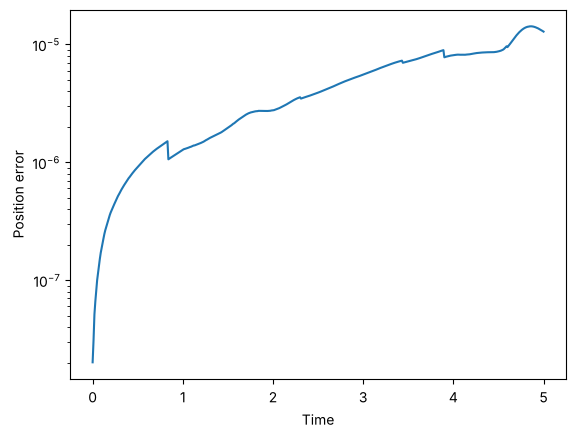

In [6]:
err_pos, err_vel, err_E = compare(r32, r64) #float64 is the reference

print('Final position error:', err_pos[-1]) #error at the last time step
print('Maximum position error:', err_pos.max()) #worst error at any time step
plt.semilogy(t, err_pos) #log scale, the error covers many orders of magnitude
plt.xlabel('Time')
plt.ylabel('Position error')
plt.show() #draw the plot

#### 3. Velocity error: 
$\epsilon_v = \|v_{32} - v_{64}\| / \|v_{64}\|$

Final velocity error: 0.00015371002556104492
Maximum velocity error: 0.00016691164625972


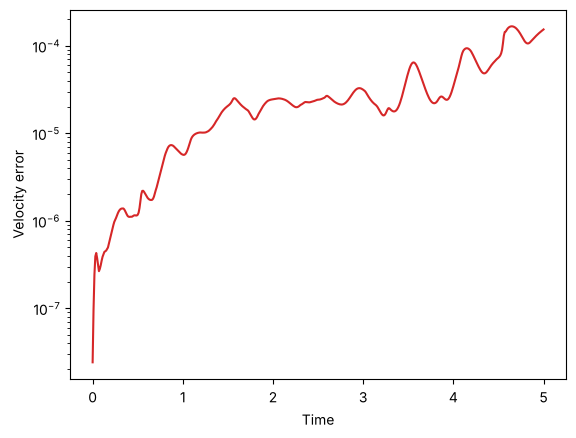

In [7]:
print('Final velocity error:', err_vel[-1]) #error at the last time step
print('Maximum velocity error:', err_vel.max()) #worst error over the whole run
plt.semilogy(t, err_vel, color='tab:red') #log scale plot in red
plt.xlabel('Time')
plt.ylabel('Velocity error')
plt.show() #draw the plot

#### 4. Energy difference:
 $\epsilon_E = |E_{32} - E_{64}| / |E_{64}|$

The ratio is only meaningful while $E_{64}$ stays away from 0. `energy_error` prints a warning if it does not (here $E \approx -43$, so it is safe).

Final energy difference: 3.1658847364724335e-05
Maximum energy difference: 4.235634083654109e-05


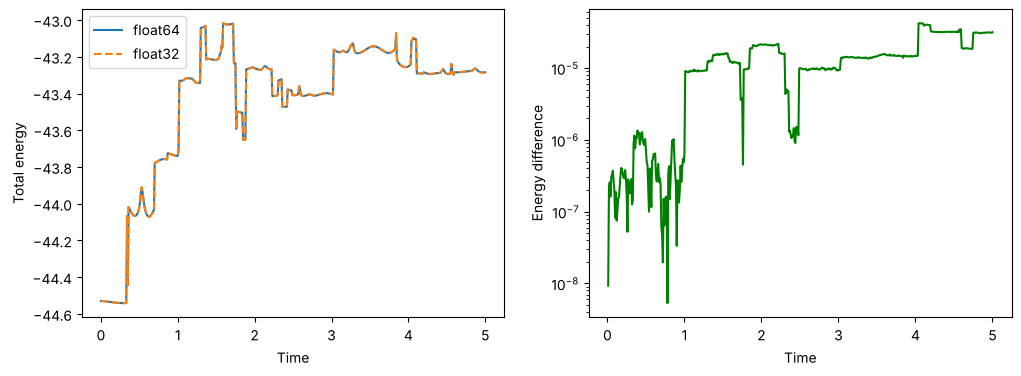

In [8]:
print('Final energy difference:', err_E[-1]) #energy gap at the last time step
print('Maximum energy difference:', err_E.max()) #biggest energy gap over the whole run

fig, ax = plt.subplots(1, 2, figsize=(12, 4)) #left: energies on top of each other, right: their difference
ax[0].plot(t, r64['E'], label='float64') #total energy in float64
ax[0].plot(t, r32['E'], '--', label='float32') #dashed line is float32, if the two lines sit on top of each other the energy matches
ax[0].set_ylabel('Total energy')
ax[0].legend() #legend is the small box that says which line is which
ax[1].semilogy(t[1:], err_E[1:], color='green') #log scale, we skip the first point because the gap at the start is 0
ax[1].set_ylabel('Energy difference')
for a in ax: #go through both plots to label the x axis
    a.set_xlabel('Time')
plt.show() #draw the plots

#### 5. Precision versus timestep

,steps,final pos error,max pos error,max vel error,max energy error
dt,,,,,
0.05,100,1.32694e-05,1.32694e-05,0.000136552,4.52569e-05
0.02,250,1.55965e-05,1.77314e-05,0.000279609,0.000247243
0.01,500,1.28481e-05,1.42464e-05,0.000166912,4.23563e-05
0.005,1000,9.80602e-06,1.01389e-05,0.000187994,0.000130311


,starts,median max pos error,worst max pos error,median max energy diff,worst max energy diff,starts with pos error > 1e-3
dt,,,,,,
0.05,8,9.6276e-06,0.00021818,9.21947e-05,0.0018634,0
0.02,8,1.26479e-05,3.89783e-05,0.000163627,0.00571594,0
0.01,8,2.96302e-05,0.00510429,0.000279395,0.0693659,1
0.005,8,5.99314e-05,0.00241255,0.00304188,0.00757256,3


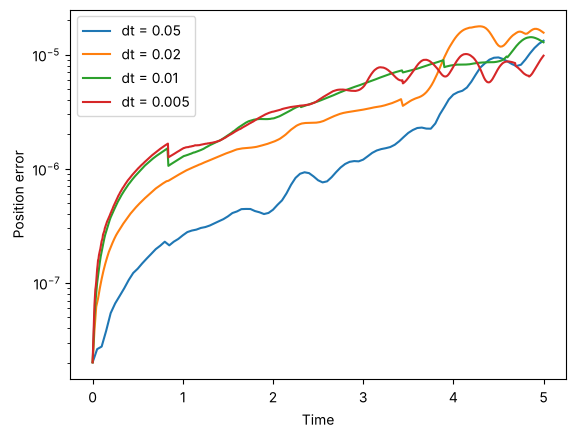

In [9]:
dts = [0.05, 0.02, 0.01, 0.005] #the four time steps we test
dt_runs, dt_err, rows = {}, {}, [] #the runs and the errors for every time step

for h in dts: #h is the time step of this run
    a = run(pos64, vel64, mass64, h, total_time, L) #float64 run with this time step
    b = run(pos32, vel32, mass32, h, total_time, L) #float32 run with the same time step
    dt_runs[h], dt_err[h] = (b, a), compare(b, a) #dt_runs stores (float32 run, float64 run)
    ep, ev, ee = dt_err[h] #pick out the three error curves (position, velocity, energy)
    rows.append({'dt': h, 'steps': len(a['E']) - 1, 'final pos error': ep[-1], 'max pos error': ep.max(), #one table row per time step, with the biggest errors seen
                 'max vel error': ev.max(), 'max energy error': ee.max()})
display(pd.DataFrame(rows).set_index('dt')) #show the table

for h in dts: #go through the time steps again for the plot
    plt.semilogy(np.arange(len(dt_err[h][0])) * h, dt_err[h][0], label=f'dt = {h}') #x axis is step number times the time step, so every curve uses real time
plt.xlabel('Time')
plt.ylabel('Position error')
plt.legend() #legend says which line is which time step
plt.show()

#The motion is chaotic, so one start can hide or exaggerate a float32 divergence. Same study for several starts:
seed_rows = [] #list that will become the table for the many starts
for h in dts:
    errs = [] #errors from every start for this time step
    for s in seeds: #seeds are different random starting positions
        p, v = initial_state(s) #new random start for this seed (Task 3/4)
        a = run(p, v, mass, h, total_time, L) #float64 run
        b = run(p.astype(np.float32), v.astype(np.float32), mass.astype(np.float32), h, total_time, L) #float32 run of the same start
        ep, ev, ee = compare(b, a)
        errs.append((ep.max(), ee.max())) #keep the worst position error and the worst energy gap of this run
    errs = np.array(errs) #turn the list into a numpy array so we can pick columns
    seed_rows.append({'dt': h, 'starts': len(errs), 'median max pos error': np.median(errs[:, 0]), 'worst max pos error': errs[:, 0].max(), #median is the middle value, so one odd run does not spoil it
                      'median max energy diff': np.median(errs[:, 1]), 'worst max energy diff': errs[:, 1].max(), #worst is the biggest value over all the starts
                      'starts with pos error > 1e-3': int((errs[:, 0] > 1e-3).sum())}) #count the starts where the position error went above 0.001
seed_table = pd.DataFrame(seed_rows).set_index('dt') #table with one row per time step
display(seed_table) #show the table

#### 6. Precision versus system size

In [10]:
sizes = [50, 200, 500, 1000] #the system sizes (number of particles) we test
size_runs, size_err, rows = {}, {}, [] #the runs and the errors for every N

for n in sizes: #go through every size
    Ln = box_for(n) #box grows with N, so the density stays the same
    p, v, m = init_particles(n, Ln, seed) #random start with n particles
    sim_time = 2.0 if n <= 200 else 0.5 #large N is slow (every step costs N^2), so those runs are shorter: 50 steps instead of 200
    a = run(p, v, m, dt, sim_time, Ln) #float64 run
    b = run(p.astype(np.float32), v.astype(np.float32), m.astype(np.float32), dt, sim_time, Ln) #float32 run of the same start
    size_runs[n], size_err[n] = (b, a, Ln), compare(b, a) #keep the runs and the errors for the later cells
    ep, ev, ee = size_err[n] #pick out the three error curves
    rows.append({'N': n, 'sim time': sim_time, 'max pos error': ep.max(), 'max vel error': ev.max(), 'max energy error': ee.max()}) #one table row per size
display(pd.DataFrame(rows).set_index('N')) #show the table

,sim time,max pos error,max vel error,max energy error
N,,,,
50,2,2.11288e-06,1.16115e-05,4.18628e-06
200,2,6.92456e-06,0.000319026,1.02976e-05
500,0.5,5.30207e-07,9.66041e-06,1.86956e-06
1000,0.5,6.51452e-07,1.72019e-05,1.16305e-06


To measure speed fairly, we timed only the force calculation (the slowest and most important part of the simulation). We ran it 5 times and used the middle result (median), because a single timing can vary due to background activity on the computer.

In [11]:
timing, rows = {}, [] #timing keeps the times, rows is for the table
for n in sizes:
    p = init_particles(n, box_for(n), seed)[0] #only the positions, the [0] picks them out
    timing[n] = {name: median_time(forces, p.astype(dtype), repeats=5)[0] for name, dtype in precisions} #median of 5 repeats, the middle time, so one slow run does not spoil it
    rows.append({'N': n, 'float64 (s)': timing[n]['float64'], 'float32 (s)': timing[n]['float32'],
                 'speedup 64/32': timing[n]['float64'] / timing[n]['float32']}) #speedup tells how many times faster float32 is (float64 time divided by float32 time)
display(pd.DataFrame(rows).set_index('N')) #show the table

,float64 (s),float32 (s),speedup 64/32
N,,,
50,0.000186021,0.000176916,1.05147
200,0.0027277,0.00239684,1.13804
500,0.0181696,0.0161193,1.1272
1000,0.0884581,0.0719486,1.22946


#### 7. Memory savings

In [12]:
#theory is N*itemsize, nbytes is the size numpy reports, measured is what numpy really allocated (traced with tracemalloc)
rows = [{'N': n, 'float32 theory': n * 4, 'float32 nbytes': np.zeros(n, np.float32).nbytes, 'float32 measured': allocated(n, np.float32),#allocated is the real memory numpy asked for, not just n*itemsize
         'float64 theory': n * 8, 'float64 nbytes': np.zeros(n, np.float64).nbytes, 'float64 measured': allocated(n, np.float64)}
        for n in [50, 200, 500, 1000, 10**4, 10**6]] #array lengths we check
display(pd.DataFrame(rows).set_index('N')) #show the table

,float32 theory,float32 nbytes,float32 measured,float64 theory,float64 nbytes,float64 measured
N,,,,,,
50,200,200,296,400,400,496
200,800,800,896,1600,1600,1696
500,2000,2000,2096,4000,4000,4096
1000,4000,4000,4096,8000,8000,8096
10000,40000,40000,40096,80000,80000,80096
1000000,4000000,4000000,4000096,8000000,8000000,8000096


In [13]:
#state = positions, velocities, masses, forces
#force peak = the most memory used while one force calculation is running
mem, rows = {}, [] #mem keeps the numbers for the later cells
for n in sizes: #go through every size
    p, v, m = init_particles(n, box_for(n), seed)
    row = {'N': n} #start a table row for this size
    for name, dtype in precisions: #do it once for float32 and once for float64
        p2, v2, m2 = p.astype(dtype), v.astype(dtype), m.astype(dtype) #same start data converted to this precision
        row[name + ' state'] = p2.nbytes + v2.nbytes + m2.nbytes + forces(p2)[0].nbytes #state is the memory of the arrays the simulation always keeps (nbytes = size of the array in bytes)
        row[name + ' force peak'] = peak_memory(forces, p2)[0] #peak is the most memory used at one moment while one force calculation runs
    row['state ratio 64/32'] = row['float64 state'] / row['float32 state'] #how many times bigger float64 is, about 2 is expected
    row['peak ratio 64/32'] = row['float64 force peak'] / row['float32 force peak'] #same ratio for the peak memory
    mem[n] = row #save the row
    rows.append({key: nice(value) if isinstance(value, int) and key != 'N' else value for key, value in row.items()}) #turn the byte counts into readable text like KiB or MiB
display(pd.DataFrame(rows).set_index('N')) #show the table

,float32 state,float32 force peak,float64 state,float64 force peak,state ratio 64/32,peak ratio 64/32
N,,,,,,
50,1.4 KiB,102.0 KiB,2.7 KiB,199.6 KiB,2,1.95782
200,5.5 KiB,1.3 MiB,10.9 KiB,2.5 MiB,2,1.96907
500,13.7 KiB,7.9 MiB,27.3 KiB,15.6 MiB,2,1.96959
1000,27.3 KiB,31.5 MiB,54.7 KiB,62.1 MiB,2,1.96967


#### 8. Numerical stability

In [14]:
#check every run: NaN/inf, speed, outside box, energy drift, dtype
#two different questions are kept apart:
#  stable   = nothing blows up (finite numbers, nobody leaves the box, no huge speed, energy does not explode, dtype kept)
#  accurate = float32 drift is the same as float64 drift (the drift itself comes from dt and the cutoff)
v_limit = 100.0 #about 10 times the largest speed seen in the float64 baseline
explosion = 1.0 #energy changing by more than 100% counts as a blow-up, this is NOT an accuracy tolerance
runs = [('baseline', r32, r64, L)] #list of (name, float32 run, float64 run, box size)
runs += [(f'dt = {h}', *dt_runs[h], L) for h in dts] #one entry for every time step
runs += [(f'N = {n}', *size_runs[n]) for n in sizes] #one entry for every system size

def drift_of(res): #drift is how far the energy has moved away from its start value
    E = res['E'].astype(np.float64) #energies in float64, so the check itself is not rounded
    assert abs(E[0]) > 0, 'E(0) = 0, relative drift is not defined' #stop with a message if the start energy is 0, because we cannot divide by 0
    return (np.abs(E - E[0]) / abs(E[0])).max() #biggest change in energy compared to the start energy

rows = []
for name, res32, res64, Lbox in runs: #go through every run
    drifts = {'float32': drift_of(res32), 'float64': drift_of(res64)}    #energy drift for both precisions
    for prec, res in [('float32', res32), ('float64', res64)]:     #do the checks once for float32 and once for float64
        finite = all(np.isfinite(res[key]).all() for key in ['pos', 'vel', 'E'])         #finite means no NaN (not a number) and no inf (infinity) anywhere in the data
        speed = np.linalg.norm(res['vel'].astype(np.float64), axis=-1).max()         #speed of every particle at every step, then the biggest one
        outside = int(((res['pos'] < 0) | (res['pos'] > res['pos'].dtype.type(Lbox))).sum())     #box edge rounded to the run precision
        ok = finite and outside == 0 and speed < v_limit and drifts[prec] < explosion and res['dtype_ok']         #ok is True only when every check passed
        rows.append({'run': name, 'precision': prec, 'finite': finite, 'max speed': speed, 'outside box': outside,      #add one table row for this run and precision
                     'max energy drift': drifts[prec], 'dtype kept': res['dtype_ok'], 'ok': ok,
                     'drift gap vs float64': abs(drifts['float32'] - drifts['float64']) if prec == 'float32' else np.nan})       #gap between the float32 drift and the float64 drift, only filled for float32 rows

stability = pd.DataFrame(rows) #table of all the checks
ok_by_run = stability.pivot(index='run', columns='precision', values='ok')      #rearrange so each run has one column for float32 and one for float64
ok_by_run = ok_by_run.loc[[r[0] for r in runs]]           #keep the rows in the same order as runs
blowup_both = list(ok_by_run.index[~ok_by_run['float64'] & ~ok_by_run['float32']])     #fails in both precisions: the time step is the cause, not the precision
only32 = list(ok_by_run.index[ok_by_run['float64'] & ~ok_by_run['float32']])          #fails only in float32: the precision is the cause
stable = pd.Series({'float32': len(only32) == 0, 'float64': True})        #'stable' for the precision question = float32 never fails where float64 works
display(stability) #show the table
print('Runs that blow up in BOTH precisions (dt problem, see Task 3):', blowup_both if blowup_both else 'none')   #print which runs failed in both precisions
print('Runs that fail ONLY in float32 (precision problem):', only32 if only32 else 'none')     #print which runs failed only in float32
print('Largest drift gap float32 vs float64, over runs that do not blow up:',
      stability[~stability['run'].isin(blowup_both)]['drift gap vs float64'].max())      #ignore the runs that blew up in both precisions

Runs that blow up in BOTH precisions (dt problem, see Task 3): none
Runs that fail ONLY in float32 (precision problem): none
Largest drift gap float32 vs float64, over runs that do not blow up: 3.4322442300248335e-05


,run,precision,finite,max speed,outside box,max energy drift,dtype kept,ok,drift gap vs float64
0,baseline,float32,True,7.63313,0,0.0339728,True,True,1.18722e-05
1,baseline,float64,True,7.63314,0,0.0339609,True,True,NaN
2,dt = 0.05,float32,True,8.39688,0,0.183928,True,True,2.64881e-05
3,dt = 0.05,float64,True,8.39686,0,0.183902,True,True,NaN
4,dt = 0.02,float32,True,9.17868,0,0.160338,True,True,2.5583e-05
5,dt = 0.02,float64,True,9.17858,0,0.160312,True,True,NaN
6,dt = 0.01,float32,True,7.63313,0,0.0339728,True,True,1.18722e-05
7,dt = 0.01,float64,True,7.63314,0,0.0339609,True,True,NaN
8,dt = 0.005,float32,True,8.77739,0,0.0496636,True,True,3.43224e-05
9,dt = 0.005,float64,True,8.77725,0,0.049698,True,True,NaN


#### 9. Final comparison

In [15]:
big = sizes[-1] #largest N, used for the memory and run time rows
all_err = list(dt_err.values()) + list(size_err.values()) #errors of all the time step runs and all the system size runs together
worst_pos = max(x[0].max() for x in all_err) #worst error over all the time step and system size runs
worst_E = max(x[2].max() for x in all_err) #worst energy gap over all runs

final_table = pd.DataFrame({ #build the final table, one column per precision
    'float32': [f'{err_pos[-1]:.3g}', f'{err_vel[-1]:.3g}', f'{err_E.max():.3g}', nice(mem[big]['float32 state']),
                nice(mem[big]['float32 force peak']), f"{timing[big]['float32'] * 1e3:.1f} ms", 'yes' if stable['float32'] else 'no'],
    'float64': ['reference'] * 3 + [nice(mem[big]['float64 state']), nice(mem[big]['float64 force peak']),
                                    f"{timing[big]['float64'] * 1e3:.1f} ms", 'reference'],
}, index=['Position error (baseline)', 'Velocity error (baseline)', 'Energy error (baseline, max)', #names of the rows
          f'State memory (N = {big})', f'Force peak memory (N = {big})', f'Force time, median of 5 (N = {big})', 'Stable wherever float64 is'])
display(final_table) #show the table

,float32,float64
Position error (baseline),1.28e-05,reference
Velocity error (baseline),0.000154,reference
"Energy error (baseline, max)",4.24e-05,reference
State memory (N = 1000),27.3 KiB,54.7 KiB
Force peak memory (N = 1000),31.5 MiB,62.1 MiB
"Force time, median of 5 (N = 1000)",71.9 ms,88.5 ms
Stable wherever float64 is,yes,reference


#### 10. Final question

In [16]:
tol_pos = 1e-3 #tolerances used to decide if float32 is accurate enough
tol_E = 1e-3 #same limit for the energy
speedup = timing[big]['float64'] / timing[big]['float32'] #how many times faster float32 is at the biggest size

failed = [(f'dt = {h}', dt_err[h][0].max(), dt_err[h][2].max()) for h in dts #collect the runs where float32 is not accurate enough
          if f'dt = {h}' not in blowup_both and (dt_err[h][0].max() > tol_pos or dt_err[h][2].max() > tol_E)] #a dt that blows up in both precisions says nothing about precision
failed += [(f'N = {n}', size_err[n][0].max(), size_err[n][2].max()) for n in sizes if size_err[n][0].max() > tol_pos or size_err[n][2].max() > tol_E] #same check for the system size runs
n_bad = int(seed_table['starts with pos error > 1e-3'].sum()) #number of starts where float32 was off by more than 0.001
n_all = int(seed_table['starts'].sum()) #total number of starts

print(f'Worst position error: {worst_pos:.3g} (tolerance {tol_pos})') #print the worst errors
print(f'Worst energy error:   {worst_E:.3g} (tolerance {tol_E})')
print('float32 fails where float64 works:', not stable['float32'], '| runs that blow up in both precisions:', blowup_both)
print(f'Single-start runs above tolerance: {failed if failed else "none"}')
print(f'Multi-start runs (5.5) with position error above tolerance: {n_bad} of {n_all}')
if not failed and n_bad == 0 and stable['float32']: #all good only if nothing failed
    print('float32 is accurate enough in every test.')
else:
    print('float32 is accurate enough in most runs, but not in all of them: a rare rounding difference at a cutoff/wall event can be amplified by the chaotic motion.')
    print('Use float32 for statistics or short runs, use float64 when an exact trajectory is needed.')
print(f'Memory ratio float64 / float32 (state): {mem[big]["state ratio 64/32"]:.2f}') #how many times more memory float64 needs, about 2
print(f'Memory ratio float64 / float32 (force peak): {mem[big]["peak ratio 64/32"]:.2f}')
print(f'Speedup of float32 at N = {big} (force calculation, median of 5): {speedup:.2f}') #print the speedup

Worst position error: 1.77e-05 (tolerance 0.001)
Worst energy error:   0.000247 (tolerance 0.001)
float32 fails where float64 works: False | runs that blow up in both precisions: []
Single-start runs above tolerance: none
Multi-start runs (5.5) with position error above tolerance: 4 of 32
float32 is accurate enough in most runs, but not in all of them: a rare rounding difference at a cutoff/wall event can be amplified by the chaotic motion.
Use float32 for statistics or short runs, use float64 when an exact trajectory is needed.
Memory ratio float64 / float32 (state): 2.00
Memory ratio float64 / float32 (force peak): 1.97
Speedup of float32 at N = 1000 (force calculation, median of 5): 1.23


# Task 7: Memory usage and scalability

#### 1. Theoretical memory: $M = N^2 \times 2 \times \text{itemsize}$

In [17]:
big_sizes = [100, 1000, 5000, 10000] #the sizes for the memory table
M32 = {n: n * n * 2 * 4 for n in big_sizes} #N*N*2 elements, 4 bytes each for float32
M64 = {n: n * n * 2 * 8 for n in big_sizes} #8 bytes each for float64

display(pd.DataFrame({'shape': [f'({n}, {n}, 2)' for n in big_sizes], #table of the array sizes in readable units (KiB, MiB, GiB)
                      'float32': [nice(M32[n]) for n in big_sizes],
                      'float64': [nice(M64[n]) for n in big_sizes]}, index=pd.Index(big_sizes, name='N')))

,shape,float32,float64
N,,,
100,"(100, 100, 2)",78.1 KiB,156.2 KiB
1000,"(1000, 1000, 2)",7.6 MiB,15.3 MiB
5000,"(5000, 5000, 2)",190.7 MiB,381.5 MiB
10000,"(10000, 10000, 2)",762.9 MiB,1.5 GiB


#### 2. Actual NumPy memory

In [18]:
free = psutil.virtual_memory().available #free memory right now, arrays bigger than half of it are skipped
print('Free memory:', nice(free)) #print the free memory

rows = [] #list for the table rows
for n in big_sizes: #go through every size
    for name, dtype in precisions: #do it for float32 and float64
        theory = n * n * 2 * np.dtype(dtype).itemsize #size the array should have: n times n times 2 numbers times bytes per number (itemsize)
        if theory > free / 2: #too big for this computer, so we skip it
            rows.append({'N': n, 'precision': name, 'theory': nice(theory), 'nbytes': 'skipped', 'measured': 'skipped', 'match': 'too large for free memory'})
        else:
            a = np.ones((n, n, 2), dtype=dtype) #make the real array and fill it, so the memory is really used
            rows.append({'N': n, 'precision': name, 'theory': nice(theory), 'nbytes': nice(a.nbytes), #nbytes is the size numpy reports for the array
                         'measured': nice(allocated((n, n, 2), dtype)), #tracemalloc, independent of the shape arithmetic
                         'match': theory == a.nbytes}) #nbytes is computed from shape and itemsize, so this alone is only a consistency check
            del a #free the memory again
display(pd.DataFrame(rows).set_index(['N', 'precision'])) #show the table

Free memory: 7.3 GiB


theory     nbytes   measured  match
N     precision                                        
100   float32     78.1 KiB   78.1 KiB   78.2 KiB   True
      float64    156.2 KiB  156.2 KiB  156.3 KiB   True
1000  float32      7.6 MiB    7.6 MiB    7.6 MiB   True
      float64     15.3 MiB   15.3 MiB   15.3 MiB   True
5000  float32    190.7 MiB  190.7 MiB  190.7 MiB   True
      float64    381.5 MiB  381.5 MiB  381.5 MiB   True
10000 float32    762.9 MiB  762.9 MiB  762.9 MiB   True
      float64      1.5 GiB    1.5 GiB    1.5 GiB   True

#### 3. Memory growth with N (a slope of 2 means $M \propto N^2$)

slope float32: 2.000000000000001
slope float64: 2.000000000000001


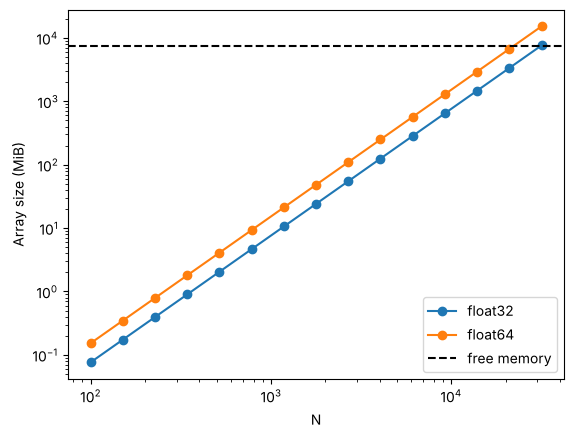

In [19]:
ns = np.unique(np.round(np.logspace(2, 4.5, 15)).astype(int)) #N from 100 to about 30000, evenly spaced on a log scale
for name, s in [('float32', 4), ('float64', 8)]: #4 bytes per number for float32, 8 bytes for float64
    M = ns ** 2 * 2 * s #array size in bytes
    print(f'slope {name}:', np.polyfit(np.log(ns), np.log(M), 1)[0]) #slope of log M against log N, 2 means M goes like N^2
    plt.loglog(ns, M / 1024**2, 'o-', label=name) #log-log plot, both axes use powers of 10, a straight line means memory grows like a power of N

plt.axhline(free / 1024**2, color='black', linestyle='--', label='free memory') #dashed line is the free memory of this computer
plt.xlabel('N')
plt.ylabel('Array size (MiB)')
plt.legend()
plt.show() #draw the plot

#### 4. float32 versus float64 memory

In [20]:
display(pd.DataFrame({'M float32': [nice(M32[n]) for n in big_sizes], #side by side table of the float32 and float64 sizes
                      'M float64': [nice(M64[n]) for n in big_sizes],
                      'ratio M64 / M32': [M64[n] / M32[n] for n in big_sizes], #how many times bigger float64 is
                      'saved': [nice(M64[n] - M32[n]) for n in big_sizes]}, index=pd.Index(big_sizes, name='N'))) #memory saved by using float32

,M float32,M float64,ratio M64 / M32,saved
N,,,,
100,78.1 KiB,156.2 KiB,2,78.1 KiB
1000,7.6 MiB,15.3 MiB,2,7.6 MiB
5000,190.7 MiB,381.5 MiB,2,190.7 MiB
10000,762.9 MiB,1.5 GiB,2,762.9 MiB


#### 5. Maximum feasible system size

N grows until the predicted peak memory is above 60% of the free memory, so the notebook never crashes.

In [21]:
def largest_size(dtype):
    budget = 0.6 * psutil.virtual_memory().available #only 60% of the free memory may be used
    ratio = 6.0 #first guess of peak/array, replaced by the measured value after every run
    rows = []
    for n in [500, 1000, 2000, 4000, 6000, 8000, 10000, 12000, 15000, 20000]: #fewer sizes than before: peak/array is constant, so the extra sizes added time but no information
        M = n * n * 2 * np.dtype(dtype).itemsize #size of the (N,N,2) array in bytes
        if ratio * M > budget: #predicted peak is too big, so stop before running this N
            print(f'  stopped before N = {n}: predicted peak is above the memory budget')
            break
        p = init_particles(n, box_for(n), seed)[0].astype(dtype) #random start with n particles in the chosen precision
        try: #try: if the computer runs out of memory we catch it below
            peak = peak_memory(forces, p)[0] #memory run (tracing switched on)
            runtime = median_time(forces, p, repeats=1)[0] #time run (tracing off, so the time is not inflated)
        except MemoryError: #MemoryError means the computer could not give more memory
            print(f'  MemoryError at N = {n}')
            break #stop the loop
        ratio = peak / M #peak memory compared to the size of the (N,N,2) array
        rows.append({'N': n, 'pair array': nice(M), 'peak memory': nice(peak), 'peak / array': ratio, 'time (s)': runtime}) #one table row for this size
    return pd.DataFrame(rows, columns=['N', 'pair array', 'peak memory', 'peak / array', 'time (s)']).set_index('N'), ratio #return the table and the last measured ratio


search = {} #search keeps the result for each precision
for name, dtype in precisions:
    print(name)
    table, ratio = largest_size(dtype) #run the search
    search[name] = {'largest': int(table.index[-1]) if len(table) else 0, 'ratio': ratio} #remember the biggest size that worked and the ratio
    display(table) #show the table

float32
  stopped before N = 12000: predicted peak is above the memory budget
float64
  stopped before N = 10000: predicted peak is above the memory budget


,pair array,peak memory,peak / array,time (s)
N,,,,
500,1.9 MiB,7.9 MiB,4.14234,0.016168
1000,7.6 MiB,31.5 MiB,4.12933,0.0737879
2000,30.5 MiB,125.9 MiB,4.12608,0.287873
4000,122.1 MiB,503.6 MiB,4.12527,1.12004
6000,274.7 MiB,1.1 GiB,4.12517,2.51462
8000,488.3 MiB,2.0 GiB,4.12513,4.54834
10000,762.9 MiB,3.1 GiB,4.1251,7.14646


,pair array,peak memory,peak / array,time (s)
N,,,,
500,3.8 MiB,15.6 MiB,4.07937,0.0174226
1000,15.3 MiB,62.1 MiB,4.06672,0.0809576
2000,61.0 MiB,248.0 MiB,4.06355,0.366813
4000,244.1 MiB,991.9 MiB,4.06276,1.41698
6000,549.3 MiB,2.2 GiB,4.06267,3.18175
8000,976.6 MiB,3.9 GiB,4.06263,5.84736


#### 6. Memory breakdown

In [22]:
def arrays_in_force_calculation(pos):
    d = pos[:, None, :] - pos[None, :, :] #(N,N,2)
    squared = d ** 2 #(N,N,2)
    summed = squared.sum(axis=-1) #(N,N)
    dist = np.sqrt(summed) #(N,N)
    nb = (dist > 0) & (dist <= r_c) #(N,N) bool, 1 byte per element in both precisions
    denominator = dist[:, :, None] + 1e-12 #(N,N,1)
    u = d / denominator #(N,N,2)
    F_mag = -k * (dist - r0) * nb #(N,N)
    weighted = F_mag[:, :, None] * u #(N,N,2)
    F = weighted.sum(axis=1) #(N,2)
    deviation = (dist - r0) ** 2 #(N,N), the temporaries of the potential energy
    shifted = deviation - (r_c - r0) ** 2 #(N,N), shift makes the pair energy zero at the cutoff
    masked = shifted * nb #(N,N)
    U = 0.25 * k * masked.sum() #U is the total spring (potential) energy
    return {'positions': pos, 'displacement (N,N,2)': d, 'squared (N,N,2)': squared, 'summed (N,N)': summed, #return all the big arrays by name, plus the force and the energy
            'distance (N,N)': dist, 'neighbours (N,N)': nb, 'denominator (N,N,1)': denominator,
            'unit vectors (N,N,2)': u, 'force magnitude (N,N)': F_mag, 'weighted (N,N,2)': weighted,
            'forces (N,2)': F, '(dist-r0)^2 (N,N)': deviation, 'shifted (N,N)': shifted, 'masked (N,N)': masked}, F, U


p = init_particles(1000, box_for(1000), seed)[0] #N = 1000
parts = {} #parts keeps the arrays of each precision
for name, dtype in precisions:
    p2 = p.astype(dtype) #convert the positions to this precision
    arrays, F_check, U_check = arrays_in_force_calculation(p2) #arrays and results from the step by step version
    F_ref, U_ref = forces(p2) #results from the normal forces() function
    assert np.allclose(F_check, F_ref, rtol=1e-4, atol=1e-4) and np.isclose(U_check, U_ref, rtol=1e-4), 'breakdown does not match forces()' #the breakdown must be the same calculation as forces()
    parts[name] = arrays #keep the arrays so we can show their sizes

display(pd.DataFrame({name: {key: nice(a.nbytes) for key, a in arrays.items()} for name, arrays in parts.items()})) #table with the size of each array in readable units
for name, dtype in precisions:
    total = sum(a.nbytes for a in parts[name].values()) #add up the sizes of all the arrays
    measured = peak_memory(forces, p.astype(dtype))[0] #measured is what the computer really used at the highest point
    print(f'{name}: all arrays together {nice(total)} (upper bound, all alive at once), measured peak of forces() {nice(measured)}') #print the sum and the measured peak for this precision

float32: all arrays together 58.2 MiB (upper bound, all alive at once), measured peak of forces() 31.5 MiB
float64: all arrays together 115.4 MiB (upper bound, all alive at once), measured peak of forces() 62.1 MiB


,float32,float64
positions,7.8 KiB,15.6 KiB
"displacement (N,N,2)",7.6 MiB,15.3 MiB
"squared (N,N,2)",7.6 MiB,15.3 MiB
"summed (N,N)",3.8 MiB,7.6 MiB
"distance (N,N)",3.8 MiB,7.6 MiB
"neighbours (N,N)",976.6 KiB,976.6 KiB
"denominator (N,N,1)",3.8 MiB,7.6 MiB
"unit vectors (N,N,2)",7.6 MiB,15.3 MiB
"force magnitude (N,N)",3.8 MiB,7.6 MiB
"weighted (N,N,2)",7.6 MiB,15.3 MiB


#### 7. Peak versus persistent memory

Persistent memory is what the simulation always keeps (positions, velocities, masses, forces). Peak memory is the extra memory used while the force calculation runs.

persistent       peak  peak / persistent
N    precision                                         
100  float32      2.7 KiB  356.1 KiB             130.24
     float64      5.5 KiB  700.6 KiB            128.114
250  float32      6.8 KiB    2.0 MiB            299.596
     float64     13.7 KiB    3.9 MiB            294.996
500  float32     13.7 KiB    7.9 MiB            591.762
     float64     27.3 KiB   15.6 MiB            582.766
1000 float32     27.3 KiB   31.5 MiB            1179.81
     float64     54.7 KiB   62.1 MiB            1161.92
2000 float32     54.7 KiB  125.9 MiB            2357.76
     float64    109.4 KiB  248.0 MiB            2322.03
3000 float32     82.0 KiB  283.3 MiB            3536.13
     float64    164.1 KiB  558.0 MiB            3482.54

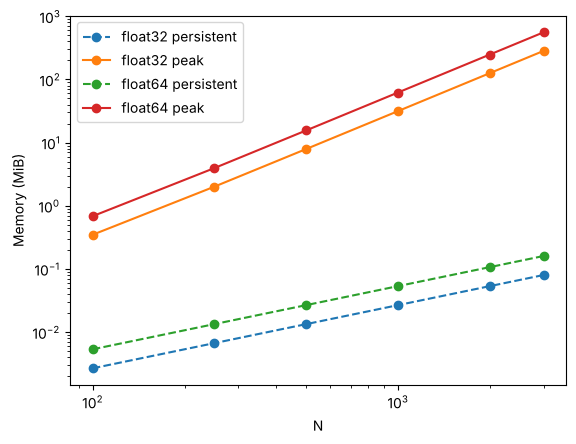

In [23]:
rows = [] #list for the table rows
for n in [100, 250, 500, 1000, 2000, 3000]:
    p, v, m = init_particles(n, box_for(n), seed)
    for name, dtype in precisions:
        p2, v2, m2 = p.astype(dtype), v.astype(dtype), m.astype(dtype) #same start data converted to this precision
        persistent = p2.nbytes + v2.nbytes + m2.nbytes + forces(p2)[0].nbytes #arrays kept for the whole run
        peak = peak_memory(forces, p2)[0] #extra memory used while the force calculation runs
        rows.append({'N': n, 'precision': name, 'persistent': persistent, 'peak': peak, 'peak / persistent': peak / persistent}) #one table row

peaks = pd.DataFrame(rows) #table of all the rows
display(peaks.assign(persistent=peaks['persistent'].map(nice), peak=peaks['peak'].map(nice)).set_index(['N', 'precision'])) #show the table with readable units

for name, _ in precisions: #one pair of lines per precision in the plot
    sub = peaks[peaks['precision'] == name] #pick only the rows of this precision
    plt.loglog(sub['N'], sub['persistent'] / 1024**2, '--o', label=name + ' persistent') #dashed line is the memory that is always kept
    plt.loglog(sub['N'], sub['peak'] / 1024**2, '-o', label=name + ' peak') #solid line is the highest memory use
plt.xlabel('N')
plt.ylabel('Memory (MiB)')
plt.legend()
plt.show() #draw the plot

#### 8. Memory scaling of different implementations

The Task 1 Python loop builds the full distance matrix first, so a loop without a matrix is included. The cell-linked list is an estimate only. The C loop (built with `compile_c_library` from Task 6) is included only if a C compiler is found; `tracemalloc` sees only the NumPy buffers passed to C, which is exactly right here because the C function allocates nothing itself.

In [24]:
#the force versions come from the earlier tasks: pair_forces (Task 1 loop), forces_python (Task 6 loop without matrix), pair_forces_vectorized (Task 6), C from compile_c_library (Task 6)
methods = {'Python loop (Task 1)': pair_forces, 'Python loop (no matrix)': forces_python, 'NumPy vectorized': pair_forces_vectorized} #all the force versions in one dictionary, so we can loop over them

forces_c, c_message = compile_c_library(Path.cwd()) #compiles for the current operating system, returns None if there is no compiler
print(c_message)
if forces_c is not None: #only if the C library was built
    methods['C loop'] = forces_c #add the C method to the dictionary

test = init_particles(200, box_for(200), seed)[0] #all methods should give the same forces as numpy
for name, f in methods.items(): #compare every method with the NumPy one
    diff = np.abs(f(test) - pair_forces_vectorized(test)).max() #biggest difference in any force value
    print(name, 'max difference from NumPy:', diff)
    assert diff < 1e-8, f'{name} does not agree with NumPy' #stop with an error if a method disagrees

Compiled C successfully with gcc -O2.
Python loop (Task 1) max difference from NumPy: 2.7758062515204074e-10
Python loop (no matrix) max difference from NumPy: 2.7758062515204074e-10
NumPy vectorized max difference from NumPy: 0.0
C loop max difference from NumPy: 2.7758062515204074e-10


,Python loop (Task 1),Python loop (no matrix),NumPy vectorized,C loop,Cell list (estimate)
N,,,,,
50,119.5 KiB,1.2 KiB,199.6 KiB,2.9 KiB,3.1 KiB
200,1.5 MiB,3.5 KiB,2.5 MiB,5.2 KiB,12.5 KiB
500,9.5 MiB,8.3 KiB,15.6 MiB,9.9 KiB,31.4 KiB
1000,38.2 MiB,16.1 KiB,62.1 MiB,17.7 KiB,62.7 KiB


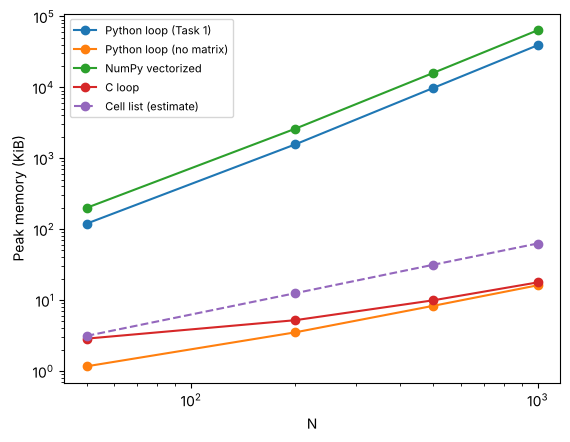

In [25]:
impl_sizes = [50, 200, 500, 1000]
impl_mem = {name: [] for name in methods} #empty list of memory values for each method
impl_mem['Cell list (estimate)'] = []

for n in impl_sizes: #go through every size
    p = init_particles(n, box_for(n), seed)[0]
    for name, f in methods.items(): #go through every method
        impl_mem[name].append(peak_memory(f, p)[0]) #peak memory of this method for this size
    impl_mem['Cell list (estimate)'].append(8 * (6 * n + max(1, int(box_for(n) // r_c)) ** 2)) #estimate only, 6N values plus one per cell, 8 bytes each

display(pd.DataFrame({name: [nice(x) for x in values] for name, values in impl_mem.items()}, index=pd.Index(impl_sizes, name='N'))) #table in readable units

for name, values in impl_mem.items(): #one line per method
    plt.loglog(impl_sizes, np.array(values) / 1024, '--o' if 'estimate' in name else '-o', label=name) #dashed line for the estimate, solid line for the measured ones
plt.xlabel('N')
plt.ylabel('Peak memory (KiB)')
plt.legend(fontsize=8) #legend with small text
plt.show()

#### 9. Memory limit prediction

With $R$ bytes of free memory and $s$ bytes per element, $N_{max} \approx \sqrt{R / (2s)}$ for the pairwise array alone. The second estimate divides $R$ by the measured peak-to-array ratio from 7.5. The size found in 7.5 is a lower bound.

In [26]:
R = psutil.virtual_memory().available #free memory in bytes
rows = [] #list for the table rows
for name, dtype in precisions:
    s = np.dtype(dtype).itemsize #bytes per element
    ratio = search[name]['ratio'] #measured peak/array from 7.5
    rows.append({'precision': name, 's (bytes)': s, 'N max (array only)': int(np.sqrt(R / (2 * s))), #sqrt(R / (2s)) is the biggest N whose (N,N,2) array fits into the free memory
                 'N max (with peak ratio)': int(np.sqrt(R / (ratio * 2 * s))), 'largest N in 7.5': search[name]['largest']}) #same, but it also counts the temporary arrays (peak ratio from 7.5)

prediction = pd.DataFrame(rows).set_index('precision') #table of the predictions
print('Free memory R:', nice(R)) #print the free memory
display(prediction) #show the table

Free memory R: 6.8 GiB


,s (bytes),N max (array only),N max (with peak ratio),largest N in 7.5
precision,,,,
float32,4,30291,14914,10000
float64,8,21419,10626,8000


#### 10. Final question

In [27]:
limit32 = prediction.loc['float32', 'N max (with peak ratio)'] #largest N predicted for float32
limit64 = prediction.loc['float64', 'N max (with peak ratio)'] #largest N predicted for float64

print(f'The vectorized calculation peaks at about {search["float64"]["ratio"]:.1f} times the pairwise array (memory grows like N squared).')
print(f'Predicted limit on this computer: N = {limit64} with float64 and N = {limit32} with float32.')
print(f'float32 raises the limit by a factor of {limit32 / limit64:.2f} (square root of 2 = {np.sqrt(2):.2f}).') #sqrt(2) is about 1.41, because float32 uses half the bytes

The vectorized calculation peaks at about 4.1 times the pairwise array (memory grows like N squared).
Predicted limit on this computer: N = 10626 with float64 and N = 14914 with float32.
float32 raises the limit by a factor of 1.40 (square root of 2 = 1.41).
